## Paso 1 — Cargamos el dataset ya tipado

Leemos directamente el Parquet, self-contenido. Este notebook cubre la
Fase 5 del plan (§6): análisis univariado — conocer la forma de cada
variable, sin cruzarlas todavía.


In [9]:
import pandas as pd
from pathlib import Path

INTERIM_DIR = Path("../datos/interim")
df = pd.read_parquet(INTERIM_DIR / "viajes_btura_tipado.parquet")

print(df.shape)


(41237, 17)


## Paso 2 — Estadísticos de las numéricas

Para cada columna: conteo de ceros y negativos por separado (ya
conocidos), y estadísticos completos calculados solo sobre los valores
positivos — mezclarlos distorsionaría media, percentiles y todo lo demás.


In [10]:
def calcular_estadisticos(serie):
    return pd.Series({
        "n": serie.count(),
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_std": serie.std(),
        "min": serie.min(),
        "max": serie.max(),
        "P1": serie.quantile(0.01),
        "P5": serie.quantile(0.05),
        "P25": serie.quantile(0.25),
        "P75": serie.quantile(0.75),
        "P95": serie.quantile(0.95),
        "P99": serie.quantile(0.99),
        "asimetria": serie.skew(),
        "curtosis": serie.kurt(),
    })

# Valores "casi-cero" ya identificados en el Paso 2 (§5.5 del plan) — se excluyen
# de este cálculo puntual, no se borran de df
valores_basura = {
    "tarifaVentaAlCliente": [1.0],
    "pesoNeto": [1.0],
}

columnas_numericas = ["distanciaTotal", "pesoNeto", "tarifaVentaAlCliente", "fleteProduccionFo"]

resultados = {}
for col in columnas_numericas:
    ceros = (df[col] == 0).sum()
    negativos = (df[col] < 0).sum()
    excluir = valores_basura.get(col, [])
    casi_cero = df[col].isin(excluir).sum()
    print(f"{col}: {ceros} ceros, {negativos} negativos, {casi_cero} casi-cero excluidos ({excluir})")
    valido = df[col][(df[col] > 0) & (~df[col].isin(excluir))]
    resultados[col] = calcular_estadisticos(valido)

tabla_estadisticos = pd.DataFrame(resultados).T.round(2)
tabla_estadisticos


    


distanciaTotal: 17 ceros, 0 negativos, 0 casi-cero excluidos ([])
pesoNeto: 82 ceros, 0 negativos, 2 casi-cero excluidos ([1.0])
tarifaVentaAlCliente: 874 ceros, 0 negativos, 3 casi-cero excluidos ([1.0])
fleteProduccionFo: 183 ceros, 1 negativos, 0 casi-cero excluidos ([])


,n,media,mediana,desv_std,min,max,P1,P5,P25,P75,P95,P99,asimetria,curtosis
distanciaTotal,41220.0,309.39,297.0,236.12,5.0,1496.0,10.00,10.0,112.0,505.0,558.0,995.0,0.47,0.58
pesoNeto,41153.0,14547.09,7155.0,12431.84,28.5,39320.0,820.68,2300.0,4000.0,26439.0,34000.0,34680.0,0.48,-1.46
tarifaVentaAlCliente,40360.0,2535953.12,2142000.0,2145200.56,20000.0,86700000.0,190000.00,289000.0,600000.0,4200000.0,5800000.0,7200000.0,5.04,157.95
fleteProduccionFo,41053.0,2487207.21,2040000.0,2072581.22,10000.0,46800000.0,190000.00,287000.0,530000.0,4200000.0,5800000.0,7000000.0,2.23,27.52


In [11]:
print("Tarifas positivas pero menores a 10.000:")
print(df[(df["tarifaVentaAlCliente"] > 0) & (df["tarifaVentaAlCliente"] < 10000)]
      [["fo", "tarifaVentaAlCliente", "fleteProduccionFo", "pesoNeto", "distanciaTotal"]])

print("\nPesos positivos pero menores a 10 kg:")
print(df[(df["pesoNeto"] > 0) & (df["pesoNeto"] < 10)]
      [["fo", "pesoNeto", "tarifaVentaAlCliente", "distanciaTotal"]])

Tarifas positivas pero menores a 10.000:
              fo  tarifaVentaAlCliente  fleteProduccionFo  pesoNeto  \
5905   301275837                   1.0           344000.0    2300.0   
5910   301275885                   1.0           190000.0    2300.0   
26499  301294966                   1.0          1800000.0    2330.0   

       distanciaTotal  
5905             10.0  
5910             10.0  
26499           332.0  

Pesos positivos pero menores a 10 kg:
             fo  pesoNeto  tarifaVentaAlCliente  distanciaTotal
7262  301243717       1.0              310000.0            10.0
7263  301243850       1.0              310000.0            10.0


## Paso 3 — Histogramas y boxplots

Para las numéricas continuas (distancia, peso), histograma normal. Para
las monetarias (tarifa, flete), además un histograma en escala
logarítmica — en escala lineal el outlier de $86,7M aplastaría toda la
visualización.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat[:2], ["distanciaTotal", "pesoNeto"]):
    df[df[col] > 0][col].hist(bins=50, ax=ax)
    ax.set_title(col)

for ax, col in zip(axes.flat[2:], ["tarifaVentaAlCliente", "fleteProduccionFo"]):
    datos = df[df[col] > 0][col]
    bins_log = np.logspace(np.log10(datos.min()), np.log10(datos.max()), 50)
    ax.hist(datos, bins=bins_log)
    ax.set_xscale("log")
    ax.set_title(f"{col} (escala log)")

plt.tight_layout()
plt.savefig("../reportes/figures/03_histogramas_numericas.png", dpi=100)
plt.show()



NameError: name 'plt' is not defined

## Paso 3 (continuación) — Boxplots

El boxplot no agrupa datos en cajones (a diferencia del histograma), así
que el cambio a escala log es directo. Los puntos fuera de los bigotes
(1.5x rango intercuartílico) son candidatos a outlier — se investigan a
fondo en la Fase 9, no aquí.


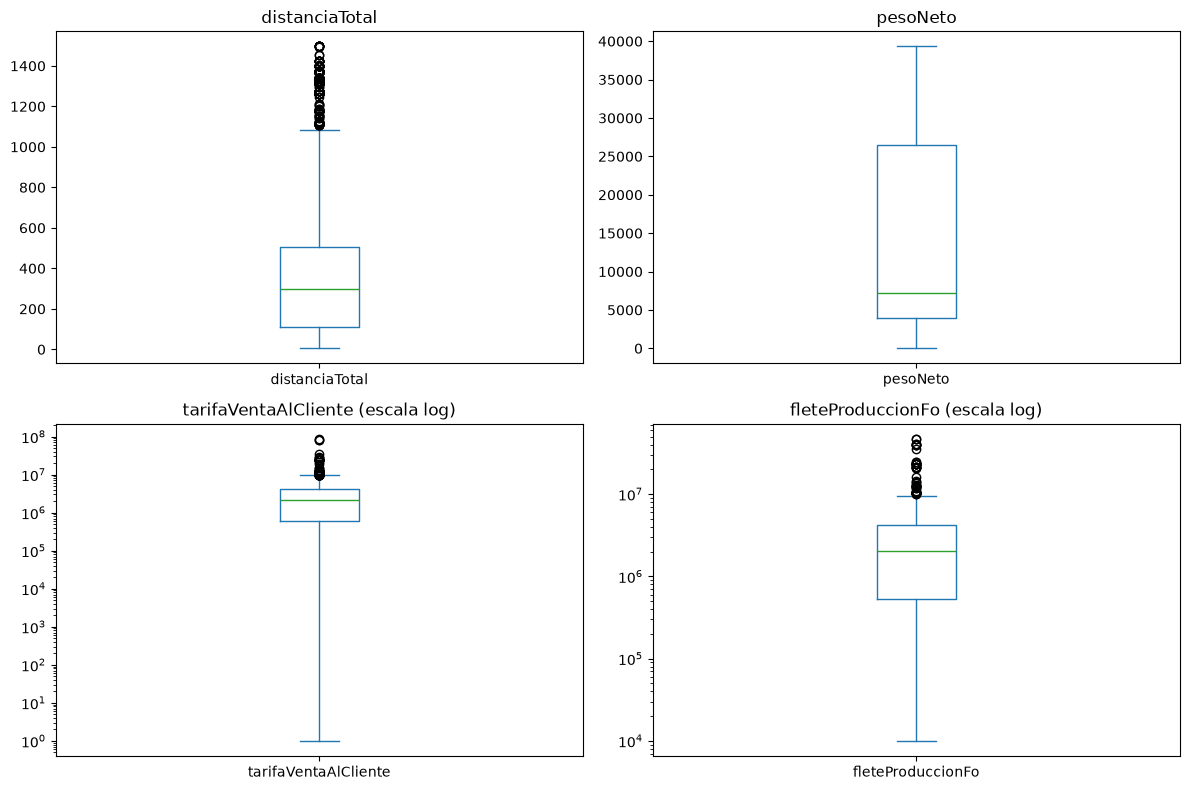

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat[:2], ["distanciaTotal", "pesoNeto"]):
    df[df[col] > 0][col].plot(kind="box", ax=ax)
    ax.set_title(col)

for ax, col in zip(axes.flat[2:], ["tarifaVentaAlCliente", "fleteProduccionFo"]):
    df[df[col] > 0][col].plot(kind="box", ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"{col} (escala log)")

plt.tight_layout()
plt.savefig("../reportes/figures/03_boxplots_numericas.png", dpi=100)
plt.show()


In [ ]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    riq = q3 - q1
    limite_superior = q3 + 1.5 * riq
    limite_inferior = q1 - 1.5 * riq
    return ((serie > limite_superior) | (serie < limite_inferior)).sum(), limite_inferior, limite_superior

for col in ["distanciaTotal", "pesoNeto", "tarifaVentaAlCliente", "fleteProduccionFo"]:
    datos = df[df[col] > 0][col]
    n_outliers, lim_inf, lim_sup = contar_outliers_iqr(datos)
    print(f"{col}: {n_outliers} outliers (límites: {lim_inf:.0f} a {lim_sup:.0f})")


distanciaTotal: 291 outliers (límites: -478 a 1094)
pesoNeto: 0 outliers (límites: -29656 a 60092)
tarifaVentaAlCliente: 88 outliers (límites: -4800000 a 9600000)
fleteProduccionFo: 51 outliers (límites: -4975000 a 9705000)


## Síntesis del Paso 3 — Histogramas, boxplots y outliers preliminares

**Formas encontradas:** `distanciaTotal` y `pesoNeto` son multimodales, no
distribuciones simples — varios "grupos" de valores típicos en vez de una
sola campana (posible reflejo de tipos de ruta y capacidades de carga
estándar; se explora en la Fase 6, bivariado). Las monetarias, en escala
log correctamente calculada, muestran una forma más simétrica concentrada
entre $100 mil y $10 millones.

**Outliers por regla IQR (1,5x), preliminar — no es el análisis formal
de la Fase 9:**

| Columna | Outliers | Límite superior |
|---|---|---|
| distanciaTotal | 291 | 1.094 km |
| pesoNeto | 0 | 60.092 kg (nunca se alcanza) |
| tarifaVentaAlCliente | 88 | $9.600.000 |
| fleteProduccionFo | 51 | $9.705.000 |

Estos números son de referencia (un solo método); el análisis serio con
múltiples métodos (IQR, z-score robusto, P99,5, IsolationForest) y
clasificación caso por caso llega en la Fase 9 (`06_outliers_y_sesgos.ipynb`).


## Paso 4 — ECDF (omitido)

Se generó y revisó, pero se descartó del notebook final: no aporta
hallazgos más allá de los ya confirmados en los Pasos 2 y 3 (percentiles
exactos e histogramas). Confirmó visualmente los saltos ya conocidos
(~10 km en distancia, ~34.000 kg en peso).


## Paso 5 — Categóricas: frecuencias y concentración

Tabla de frecuencias completa (con nulos) para las categóricas de baja
cardinalidad, y el índice de concentración top-5 para todas, incluyendo
las de alta cardinalidad (origen, destino, vehiculo).


In [ ]:
columnas_categoricas = [
    "idClaseDocumentoFwo", "posicionPrincipalFwop", "grupoDeEquipoFwop",
    "claseEquipoFop", "propiedad", "idMedioTransporteFo", "tipo",
]

for col in columnas_categoricas:
    print(f"\n--- {col} ---")
    conteo = df[col].value_counts(dropna=False)
    pct = df[col].value_counts(dropna=False, normalize=True) * 100
    print(pd.DataFrame({"conteo": conteo, "pct": pct.round(2)}))

print("\n\nÍndice de concentración (top 5 categorías, % del total):")
for col in columnas_categoricas + ["origen", "destino", "vehiculo"]:
    top5_pct = df[col].value_counts(normalize=True).head(5).sum() * 100
    print(f"{col}: {top5_pct:.1f}%")



--- idClaseDocumentoFwo ---
                     conteo    pct
idClaseDocumentoFwo               
OPIM                  27813  67.45
OHUB                   6092  14.77
OPEX                   3877   9.40
OH3P                   1871   4.54
OPTN                   1497   3.63
OPDS                     65   0.16
OPTI                     22   0.05

--- posicionPrincipalFwop ---
                       conteo    pct
posicionPrincipalFwop               
TUR                     33741  81.82
PRD                      6197  15.03
PKG                      1299   3.15

--- grupoDeEquipoFwop ---
                   conteo    pct
grupoDeEquipoFwop               
CN                  28353  68.76
NaN                  7496  18.18
CAM                  5388  13.07

--- claseEquipoFop ---
                conteo    pct
claseEquipoFop               
CNT40.HC         19426  47.11
NaN               7499  18.19
CNT20.ST          7308  17.72
3S3.34T           3323   8.06
C2.4.5T           1062   2.58
CNT40.RE      

## Síntesis del Paso 5 — Categóricas

Frecuencias completas reproducidas, coinciden con el baseline del plan.
Concentración real (no trivial): `origen` 83,4% en 5 de 113 ciudades,
`claseEquipoFop` 94% en 5 de 28 clases. Contraste sano: `vehiculo` solo
12,6% en top-5 de 3.418 — la flota sí está distribuida, la concentración
de las demás columnas es un patrón de negocio real, no un artefacto de
medición.

Hallazgo lateral: cola de 13 categorías de `claseEquipoFop` con 1-7
registros cada una, con nombres muy parecidos a la categoría dominante
(`CNT40.HC`) — candidatas a error de digitación (§5.4 del plan). No se
investiga a fondo aquí, queda anotado.


## Paso 6 — Distribución por día de la semana

¿Hay actividad los domingos? Comparamos contra el promedio de días
laborales para responderlo con un número, no a ojo.


In [ ]:
df["dia_semana"] = df["fechaCreacionFo"].dt.day_name()
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
por_dia_semana = df["dia_semana"].value_counts().reindex(orden_dias)

print("Registros por día de la semana:")
print(por_dia_semana)

promedio_laboral = por_dia_semana[:5].mean()
print(f"\nPromedio lunes-viernes: {promedio_laboral:.0f}")
print(f"Sábado: {por_dia_semana['Saturday']}")
print(f"Domingo: {por_dia_semana['Sunday']}")


Registros por día de la semana:
dia_semana
Monday       6043
Tuesday      8154
Wednesday    6397
Thursday     6320
Friday       7390
Saturday     5484
Sunday       1449
Name: count, dtype: int64

Promedio lunes-viernes: 6861
Sábado: 5484
Domingo: 1449


## Síntesis del Paso 6 — Día de la semana

Actividad real los fines de semana: sábado ~80% del promedio laboral,
domingo ~21% (no cero) — descarta que la operación se detenga
completamente el fin de semana, y refuerza que `fechaCreacionFo` sigue de
cerca la operación real (contraste con el 25-dic, único día en 0 de toda
la ventana). Martes muestra volumen notablemente más alto que otros días
laborales — pendiente de explorar en la Fase 7 (notebook 05) si se
retoma.


## Paso 7 — Redundancia entre columnas de equipo (V de Cramér)

Medimos asociación entre las 5 columnas relacionadas con vehículo/equipo,
para determinar cuántas dimensiones de información realmente distintas
hay detrás de ellas.


In [ ]:
from scipy.stats.contingency import association

columnas_equipo = ["tipo", "idMedioTransporteFo", "claseEquipoFop", "grupoDeEquipoFwop", "vehiculo"]

matriz_cramer = pd.DataFrame(index=columnas_equipo, columns=columnas_equipo, dtype=float)

for i, col1 in enumerate(columnas_equipo):
    for j, col2 in enumerate(columnas_equipo):
        if i == j:
            matriz_cramer.loc[col1, col2] = 1.0
        elif j > i:
            tabla = pd.crosstab(df[col1], df[col2])
            v = association(tabla, method="cramer")
            matriz_cramer.loc[col1, col2] = v
            matriz_cramer.loc[col2, col1] = v

matriz_cramer.round(2)


,tipo,idMedioTransporteFo,claseEquipoFop,grupoDeEquipoFwop,vehiculo
tipo,1.00,0.83,0.29,0.51,1.00
idMedioTransporteFo,0.83,1.00,0.33,0.52,0.94
claseEquipoFop,0.29,0.33,1.00,1.00,0.54
grupoDeEquipoFwop,0.51,0.52,1.00,1.00,0.88
vehiculo,1.00,0.94,0.54,0.88,1.00


## Paso 7 (continuación) — Verificando el 1.00 sospechoso

`Vehículo` tiene 3.418 categorías y `Tipo` solo 18. Con esa diferencia de
cardinalidad, la V de Cramér puede inflarse artificialmente hacia 1 aunque
la relación real no sea tan fuerte (tabla de contingencia muy dispersa).
Antes de aceptar el 1.00 entre `Vehículo` y `Tipo`, lo verificamos de forma
directa: por cada placa, ¿cuántos valores distintos de `Tipo` tiene a lo
largo del dataset? Si el método estuviera inflando el número, esperaríamos
encontrar bastantes vehículos con más de un valor.


In [ ]:
tipos_por_vehiculo = df.groupby("vehiculo")["tipo"].nunique()
medio_por_vehiculo = df.groupby("vehiculo")["idMedioTransporteFo"].nunique()

n_veh = tipos_por_vehiculo.shape[0]
print(f"Vehículos con más de un Tipo distinto: {(tipos_por_vehiculo > 1).sum()} de {n_veh} "
      f"({(tipos_por_vehiculo > 1).mean()*100:.2f}%)")
print(f"Vehículos con más de un ID Medio Transporte FO distinto: {(medio_por_vehiculo > 1).sum()} de {n_veh} "
      f"({(medio_por_vehiculo > 1).mean()*100:.2f}%)")

print("\nFilas por vehículo (para confirmar que hay repetición suficiente para que el chequeo sea válido):")
print(df.groupby("vehiculo").size().describe())


Vehículos con más de un Tipo distinto: 0 de 3418 (0.00%)
Vehículos con más de un ID Medio Transporte FO distinto: 64 de 3418 (1.87%)

Filas por vehículo (para confirmar que hay repetición suficiente para que el chequeo sea válido):
count    3418.000000
mean       12.064658
std        48.119391
min         1.000000
25%         1.000000
50%         3.000000
75%         8.000000
max      1204.000000
dtype: float64


## Síntesis del Paso 7 — Redundancia entre columnas de equipo

La matriz de V de Cramér mostró dos asociaciones perfectas (1.00):
`Vehículo`↔`Tipo` y `Clase Equipo FOP`↔`Grupo de Equipo FWOP`. Antes de
aceptar la primera se verificó si era un artefacto del método (`Vehículo`
tiene 3.418 categorías contra solo 18 de `Tipo`, lo que puede inflar la V
con tablas de contingencia muy dispersas).

**Verificado directamente: 0 de 3.418 vehículos (placas) tienen más de un
`Tipo` distinto**, con un promedio de 12 filas por vehículo (mediana 3) —
repetición suficiente para descartar que sea casualidad por dispersión.
El 1.00 es real: el tipo de camión es un atributo físico fijo de cada
placa. `ID Medio Transporte FO`, en cambio, sí varía en 64 vehículos
(1,87 %) — coherente con el 13,1 % de discrepancia `Tipo`↔`ID Medio
Transporte FO` ya encontrado en el notebook `02` (dos catálogos que no
siempre coinciden).

**Conclusión — de 5 columnas, quedan 2 dimensiones reales de
información:**

1. **Tipo de camión** — representado de forma redundante por `Vehículo`,
   `Tipo` e `ID Medio Transporte FO`. Ya se había resuelto (notebook `02`,
   §5.4) que `Tipo` es el menos confiable ("puede omitirse" según el
   diccionario) → usar **`ID Medio Transporte FO`** como fuente de verdad
   de esta dimensión. `Vehículo` se conserva aparte, no como categoría
   sino como identificador (la placa), útil para frecuencia/trazabilidad.
2. **Tipo de equipo/contenedor** — `Clase Equipo FOP` (27 valores) y
   `Grupo de Equipo FWOP` (2 valores: CN/CAM) son el mismo dato en dos
   niveles de detalle (asociación perfecta, coherente con la jerarquía ya
   documentada en §3.2/§5.1: aplica solo a la posición TUR). Usar
   **`Clase Equipo FOP`** cuando se necesite el detalle; `Grupo de Equipo
   FWOP` para la versión agregada.

**Recomendación para el resto del EDA:** evitar repetir el mismo análisis
con las 5 columnas por separado — tratar `ID Medio Transporte FO` +
`Clase Equipo FOP` como las dos dimensiones reales, y `Vehículo` como
identificador aparte.


## Síntesis del notebook 03 — Análisis univariado

**Objetivo cumplido (Fase 5, §6 del plan):** conocer la forma de cada
variable por separado, antes de cruzarlas entre sí.

**Numéricas (Pasos 2-4):** además de los ceros y negativos ya conocidos,
aparecieron valores "casi-cero" no detectados antes: 3 tarifas en
exactamente $1 y 2 pesos en exactamente 1 kg — mismo problema que los
ceros, solo que disfrazado (ya incorporado al conteo funcional del plan,
§5.5). Las distribuciones de `distanciaTotal` y `pesoNeto` son
multimodales, no una sola campana — reflejo probable de tipos de ruta y
capacidades de carga estándar, a explorar en el bivariado. Outliers
preliminares por IQR (referencia, no el análisis formal): 291 en
distancia, 88 en tarifa, 51 en flete, 0 en peso. El ECDF (Paso 4) se
generó y se descartó del notebook final por no aportar nada nuevo frente
a percentiles e histogramas.

**Categóricas (Paso 5):** frecuencias confirmadas contra el baseline del
plan. La concentración alta en varias columnas (`origen` 83,4%,
`claseEquipoFop` 94%) es patrón real de negocio, no artefacto — lo
confirma el contraste con `vehiculo`, que solo concentra 12,6% en su
top-5 (la flota sí está repartida). Hallazgo lateral sin resolver: una
cola de 13 categorías de `claseEquipoFop` con 1-7 registros y nombres muy
parecidos a la dominante (`CNT40.HC`) — candidatas a error de
digitación, anotado pero no investigado a fondo.

**Fecha (Paso 6):** hay actividad real los fines de semana (sábado ~80%
del promedio laboral, domingo ~21%) — descarta que el negocio se detenga
por completo, y refuerza que `fechaCreacionFo` sigue de cerca la
operación real. Martes muestra un volumen notablemente más alto que los
demás días laborales, sin explicación todavía — queda para el notebook
`05` si se retoma el análisis temporal a fondo.

**Redundancia de equipo (Paso 7):** de las 5 columnas que describen
vehículo/equipo, solo hay **2 dimensiones reales de información**: tipo
de camión (`idMedioTransporteFo` como fuente de verdad; `tipo` se
descarta; `vehiculo` se conserva como identificador aparte) y tipo de
equipo/contenedor (`claseEquipoFop`, con `grupoDeEquipoFwop` como su
versión agregada). Verificado con evidencia directa (0 de 3.418
vehículos con más de un `tipo` distinto), no solo con el estadístico.

**Qué le queda listo a los notebooks siguientes:**
- `04_bivariado_multivariado.ipynb`: usar `idMedioTransporteFo` +
  `claseEquipoFop` como las dos variables categóricas de equipo — no
  repetir el cruce con las 5 columnas originales.
- `05_temporal_y_geografico.ipynb`: profundizar el patrón de martes alto
  y la estacionalidad completa (año, mes, semana) — aquí solo se tocó
  día de la semana.
- `06_outliers_y_sesgos.ipynb`: los outliers IQR del Paso 3 son
  preliminares (un solo método, sin segmentar por tipo de vehículo) — el
  análisis formal con múltiples métodos y clasificación caso por caso va
  ahí.
- Pendiente sin dueño: la cola de `claseEquipoFop` con posibles errores
  de digitación (Paso 5).
